# Figure 6: Change-Point Summary

Translation of `Figure06_cpSummary.m`

## What this notebook does

Characterizes how participants adjust their decision bounds in response to a **change point (CP)**
in the generative process. In CP trials the SNR shifts mid-block at a random time; the optimal
response is to increase or decrease the bound to maximize reward rate (RR) at the new SNR.

All statistics are computed once, early in the notebook, and plotted only once — in the
**Formatted figure** section near the end. There are no separate "preview" plots above; the
computation cells below print their results as text so you can sanity-check numbers before the
combined figure is built.

**3-row, 2-column figure layout** (columns = LowHigh / HighLow CP directions). Each row uses its
own, deliberately distinct visual encoding, since the three rows show unrelated quantities:

- **Row 1 — Example RR curve**: One example subject's smoothed RR vs. bound curve at their
  actual CP step, with markers at the pre-CP bound (open circle), optimal bound (blue ★), and
  post-CP bound (filled black circle).
- **Row 2 — Bound change vs. RR gradient**: one panel per condition. The x-axis is `gradient`
  — the RR secant slope from the pre-CP bound to the RR-optimal bound, signed automatically
  (positive = should raise, negative = should lower). should-raise and should-lower subjects are
  analyzed as separate groups (see "Why split by direction instead of pooling by sign" below), but
  each panel is annotated with **all three** relevant Spearman correlations, each with its own n
  — pooled (non-split), should-raise only, and should-lower only — so the pooled number stays
  visible alongside the split that motivates it. Point fill color encodes the subject's raw
  pre-CP bound on a dedicated blue-red gradient (shared scale across both panels, distinct from
  Row 3 panel F's viridis RR heatmap); point edge color marks direction by the sign of gradient
  (black = should-raise, light gray = should-lower).
- **Row 3 — Post-CP bound comparison**: Left (panel E): LowHigh post-CP bound vs. HighLow
  post-CP bound (Wilcoxon signed-rank p-value). Right (panel F): Low bound vs. High bound in the
  corresponding stable-SNR (no-CP) conditions, with the expected reward-rate landscape drawn as a
  background heatmap (near-optimal region outlined in blue, peak marked with a blue star),
  matching the manuscript's Fig. 6F and the heatmap styling used in `Figure05_mixedVsBlockedSNR.ipynb`.

## Statistical tests

Computed once, right after the RR benchmark, and used both as Row 2 panel annotations and
throughout "Key findings" below:

1. **Spearman correlation, bound change vs. RR gradient** — pooled (non-split) and separately
   within should-raise / should-lower subjects (`spearman_pooled`, `spearman_branch`), plus a
   Wilcoxon signed-rank test of whether each branch's median bound change differs from zero
   (`wilcoxon_branch`).
2. **Spearman correlation, bound change vs. raw pre-CP bound** (`spearman_prebound`) — an
   independent question, since pre-CP bound is not the same quantity as gradient.

## Data requirements

Per-subject CP bound summaries are computed directly from raw data at the top of this notebook
(`get_data_table(task_type='MXSC')` + `pigeon.data.get_bound_summaries_wcp`) --
fields: `LowHigh` (n_subjects × 2: [pre-CP bound, post-CP bound] for Low→High transitions),
`HighLow`, `Low`, `High`, `CPLowHigh` (CP step per subject), `CPHighLow`.

The reward-rate matrices are the one piece still loaded from a pre-computed file, since they take
hours to simulate:

**`RRMats.mat`**: Reward-rate matrices from `Make_RRMatrix.ipynb` with `COMPUTE_CP = True`.
Fields: `pmats` (1×2 cell array — `pmats{1}` = LowHigh matrix, `pmats{2}` = HighLow matrix,
each `n_bounds × n_bounds × n_cp_steps`), `bounds`, `cp_steps_lh`, `cp_steps_hl`, `g_means`,
`g_std`. Must be built with `G_MEANS = [0.01, 0.02]` and `G_STD = 0.05` to match the actual
pigeon task parameters.

Panel F's reward-rate landscape is *not* loaded from a file — it's computed inline via
`pigeon.simulation.get_simulated_data_table` (specs mode), since it only needs cohort 3's known
generative parameters.


## Key findings

*(Read this first — the analysis and figure below support these results.)*

### Why the RR gradient, and why split should-raise/should-lower subjects

The benchmark used throughout is the raw RR secant slope, `gradient = (RR_opt - RR_pre) /
(bound_opt - bound_pre)`, signed automatically (positive = should raise, negative = should lower,
since RR_opt ≥ RR_pre always). This is the same quantity used to build the manuscript's Fig. 6C/D.

Pooling should-raise and should-lower subjects onto one signed gradient axis hides a real effect
in HighLow: splitting at gradient = 0 shows a strong, reliable relationship among should-lower
subjects (ρ=+0.70, p=0.0006, n=20) sitting right next to a null one among should-raise subjects
(ρ=−0.14, p=0.45, n=32) — averaging the two gives a much weaker pooled correlation. LowHigh
doesn't show this problem, not because its definitions are better, but because it has essentially
no should-lower subjects to begin with (4 of 56, all landing on a degenerate zero gradient from
bin quantization and excluded from the correlations below).

### Bound change vs. RR gradient (Row 2 / panels C, D)

Excluding the 4 subjects already at their optimal bin (zero gradient, undefined sign) leaves
n=52 in both conditions:

- **LowHigh**: pooled ρ=+0.318, p=0.0215 (n=52). Essentially all eligible subjects are
  should-raise (should-lower n=0), so the should-raise correlation is identical to the pooled one.
- **HighLow**: pooled ρ=+0.270, p=0.0524 (n=52) — but this pools over two very different
  sub-populations: should-raise (n=32) shows no relationship (ρ=−0.140, p=0.446), while
  should-lower (n=20) shows a strong one (ρ=+0.700, p=0.0006).

**Comparison to the manuscript:** Fig. 6C/D report ρ=0.34 (p=0.011, LowHigh) and ρ=0.26
(p=0.048, HighLow) for this same pooled gradient correlation. The pooled numbers recomputed here
(+0.318 / +0.270) are close to both — well within the range expected from re-simulating the RR
matrices (`RRMats.mat` was regenerated with `num_reps=5000` to reduce small-bound simulation
noise; see `Make_RRMatrix.ipynb`) rather than an exact byte-for-byte reproduction. The HighLow
number in particular sits right at the p≈0.05 boundary either way, so the split above is the more
informative decomposition of that result, not a contradiction of it.

### Pre-CP bound vs. bound change (independent test, whole condition, not split)

Both conditions show a significant *negative* relationship between a subject's raw pre-CP bound
and their bound change — **LowHigh**: ρ=−0.302, p=0.024; **HighLow**: ρ=−0.416, p=0.0013. Higher
pre-CP bound predicts a smaller (or more negative) bound change in both conditions, on top of (or
instead of) whatever the RR gradient captures — subjects who started with an already-high bound
tend to raise it less or cut it more, a pattern consistent with reversion toward a preferred bound
level as much as with RR-optimal tracking.

**Caveat:** this is a model-based account — it explains what the RR matrix says is optimal given
each subject's actual pre-CP bound and CP step, not direct evidence of what participants compute.


In [1]:
import sys
sys.path.insert(0, '..')

import os
import numpy as np
import scipy.io
import scipy.stats
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.colors as mcolors

from pigeon.data import get_data_table
from pigeon.data import get_bound_summaries_wcp
from pigeon.pathDefaults import BIAS_CORRECTION_CP_FILE, RR_MATS_FILE, FIGURES_DIR
from pigeon.plotting import FONT_RC, add_panel_label
from pigeon.simulation import get_simulated_data_table

# BOUNDS is loaded from RR_MATS_FILE below (cell that loads pmats) -- it is the
# actual, possibly non-uniform CP-scale grid Make_RRMatrix.ipynb built the RR
# matrices with, not a hardcoded MX-style uniform grid.

# Condition labels and example subject indices (MATLAB 1-indexed: tt=1→pp=53, tt=2→pp=52)
TITLES           = ['LowHigh', 'HighLow']
EXAMPLE_SUBJECTS = {0: 52, 1: 51}   # 0-indexed -- chosen against an older subject
# ordering; may not point at a representative-looking example subject now that
# get_data_table reads Pigeon_MXSC's current 60-subject cohort. Revisit if Row 1's
# example panel looks off.

# Row 2's pre-CP-bound color scale: a dedicated blue-red gradient, distinct from
# Row 3 panel F's viridis RR heatmap, since the two rows encode unrelated quantities
# (a per-subject bound value vs. a simulated reward rate).
PRE_BOUND_CMAP = mcolors.LinearSegmentedColormap.from_list('blue_red', ['tab:blue', 'tab:red'])

## Load data

Bound summaries are computed directly from the raw CP data (`get_data_table` +
`get_bound_summaries_wcp`) -- fast enough (seconds) that caching them via a
separate notebook + `.mat` file bought nothing but a staleness risk (see git
history: this used to load a pre-computed `NEW_boundSummaries_wCP.mat` from
`Make_cpBoundSummaries.ipynb`, which silently went stale multiple times across
data-source and bias-correction fixes). Only the RR matrices are still loaded
from a pre-computed file, since `Make_RRMatrix.ipynb` takes hours to run --
raises `FileNotFoundError` with a clear message if it's missing.

**Data included**: All subjects from the CP task; all unique CP times.

**Data excluded**: Subjects with non-finite pre- or post-CP bounds (`isfinite` filter applied
during plotting).

In [2]:
data_table_mxsc = get_data_table(
    task_type='MXSC',
    combine_snr=False, correct_bias=BIAS_CORRECTION_CP_FILE,
)
bound_summaries = get_bound_summaries_wcp(data_table_mxsc)

lh_bounds = np.asarray(bound_summaries['LowHigh'])    # (n_subjects, 2): col 0 = pre-CP, col 1 = post-CP
hl_bounds = np.asarray(bound_summaries['HighLow'])
lo_bounds = np.asarray(bound_summaries['Low'])        # stable Low blocks: (n_subjects, 2)
hi_bounds = np.asarray(bound_summaries['High'])       # stable High blocks
cp_lh     = np.asarray(bound_summaries['CPLowHigh'])  # (n_subjects,): CP step for LowHigh trials
cp_hl     = np.asarray(bound_summaries['CPHighLow'])

if not os.path.exists(RR_MATS_FILE):
    raise FileNotFoundError(
        f'{RR_MATS_FILE!r} not found.\n'
        'This file is generated by Make_RRMatrix.ipynb with COMPUTE_CP = True.'
    )

# Load RR matrices: pmats is a 2-element cell → Python list of arrays
# pmats[0] = LowHigh RR matrix (n_bounds × n_bounds × n_lh_cp_steps)
# pmats[1] = HighLow RR matrix (n_bounds × n_bounds × n_hl_cp_steps)
# Separate cp_steps arrays because LowHigh and HighLow have different unique CP steps.
rr_mat = scipy.io.loadmat(RR_MATS_FILE, squeeze_me=True, struct_as_record=False)

# The bound grid the RR matrix was actually built with (Make_RRMatrix.ipynb's
# CP_BOUNDS) -- loaded from the file, not hardcoded, since it is CP-scale
# specific and non-uniformly spaced (see Make_RRMatrix.ipynb).
BOUNDS = np.atleast_1d(rr_mat['bounds']).astype(float)
pmats  = list(rr_mat['pmats'].flat)

if 'cp_steps_lh' not in rr_mat or 'cp_steps_hl' not in rr_mat:
    raise KeyError(
        "RRMats.mat uses the old format (single 'cp_steps' field).\n"
        "Regenerate by running Make_RRMatrix.ipynb with COMPUTE_CP = True.\n"
        "The new format stores separate 'cp_steps_lh' and 'cp_steps_hl' fields "
        "so that each condition's matrix uses the actual unique CP steps from the data."
    )

cp_steps_lh      = rr_mat['cp_steps_lh']    # CP steps for LowHigh matrix (3rd axis)
cp_steps_hl      = rr_mat['cp_steps_hl']    # CP steps for HighLow matrix (3rd axis)
cp_steps_by_cond = [cp_steps_lh, cp_steps_hl]

print(f'LowHigh:  median [IQR] CP step = '
      f'{np.percentile(cp_lh, 50):.1f} [{np.percentile(cp_lh, 25):.1f} '
      f'{np.percentile(cp_lh, 75):.1f}]')
print(f'HighLow:  median [IQR] CP step = '
      f'{np.percentile(cp_hl, 50):.1f} [{np.percentile(cp_hl, 25):.1f} '
      f'{np.percentile(cp_hl, 75):.1f}]')
print(f'Matrix LowHigh CP steps ({len(cp_steps_lh)}): {cp_steps_lh[0]}–{cp_steps_lh[-1]}')
print(f'Matrix HighLow CP steps ({len(cp_steps_hl)}): {cp_steps_hl[0]}–{cp_steps_hl[-1]}')

  1: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MXSC/CP25-S001_PigeonTask_2025-03-21_12h24.23.977.csv
  2: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MXSC/CP25-S002_PigeonTask_2025-02-18_17h54.36.397.csv
  3: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MXSC/CP25-S003_PigeonTask_2025-03-21_12h57.38.965.csv
  4: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MXSC/CP25-S004_PigeonTask_2025-03-23_21h15.14.332.csv
  5: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MXSC/CP25-S005_PigeonTask_2025-03-23_20h43.17.071.csv
  6: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MXSC/CP25-S006_PigeonTask_2025-02-24_20h40.37.408.csv
  7: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Pr

 14: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MXSC/CP25-S014_PigeonTask_2025-03-24_02h52.21.402.csv
 15: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MXSC/CP25-S015_PigeonTask_2025-03-21_11h27.18.572.csv
 16: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MXSC/CP25-S016_PigeonTask_2025-03-21_11h27.41.827.csv
 17: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MXSC/CP25-S017_PigeonTask_2025-03-21_12h41.33.604.csv
 18: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MXSC/CP25-S018_PigeonTask_2025-03-24_02h52.25.448.csv
 19: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MXSC/CP25-S019_PigeonTask_2025-03-21_13h28.42.502.csv
 20: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Pr

 25: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MXSC/CP25-S025_PigeonTask_2025-03-24_01h47.26.422.csv
 26: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MXSC/CP25-S026_PigeonTask_2025-03-24_01h23.39.974.csv
 27: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MXSC/CP25-S027_PigeonTask_2025-03-24_11h54.39.784.csv
 28: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MXSC/CP25-S028_PigeonTask_2025-02-25_14h48.09.227.csv
 29: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MXSC/CP25-S029_PigeonTask_2025-03-24_00h55.08.971.csv
 30: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MXSC/CP25-S030_PigeonTask_2025-03-21_12h23.50.277.csv
 31: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Pr

 38: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MXSC/CP25-S038_PigeonTask_2025-03-21_11h25.55.356.csv
 39: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MXSC/CP25-S039_PigeonTask_2025-03-21_11h25.51.742.csv
 40: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MXSC/CP25-S040_PigeonTask_2025-02-24_20h42.34.120.csv
 41: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MXSC/CP25-S041_PigeonTask_2025-02-18_12h08.52.663.csv
 42: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MXSC/CP25-S042_PigeonTask_2025-02-18_12h19.13.907.csv
 43: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MXSC/CP25-S043_PigeonTask_2025-02-19_09h47.11.697.csv
 44: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Pr

 50: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MXSC/CP25-S050_PigeonTask_2025-03-21_11h25.49.743.csv
 51: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MXSC/CP25-S051_PigeonTask_2025-03-21_11h32.32.706.csv
 52: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MXSC/CP25-S052_PigeonTask_2025-03-21_11h45.24.335.csv
 53: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MXSC/CP25-S053_PigeonTask_2025-03-21_12h26.17.699.csv
 54: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MXSC/CP25-S054_PigeonTask_2025-03-21_13h25.44.084.csv
 55: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MXSC/CP25-S055_PigeonTask_2025-03-23_19h44.52.385.csv
 56: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Pr

LowHigh:  median [IQR] CP step = 9.5 [8.0 15.0]
HighLow:  median [IQR] CP step = 8.0 [6.8 11.0]
Matrix LowHigh CP steps (19): 3–27
Matrix HighLow CP steps (19): 2–32


/Users/jigold/miniconda3/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/notebooks/../pigeon/data.py:1111: RuntimeWarning: Mean of empty slice
  Acc_summary[ii, 1] = np.nanmean(cond_table.loc[Ls, "correct"]) if Ls.any() else np.nan


## Rows 1–2: Example RR curve and bound change vs. gradient, split by direction

Computed here; plotted together with Row 3 in the single **Formatted figure** section near the
end of this notebook (no separate preview plots).

**Row 1** shows one example subject's smoothed RR vs. bound curve at their actual CP step, with
markers at the pre-CP bound (open circle), optimal post-CP bound (blue ★), and actual post-CP
bound (filled black circle).

**Row 2** shows each subject's bound change (post − pre CP) against the RR gradient (secant slope
from the pre-CP bound to the RR-optimal bound). gradient is signed automatically (positive =
should raise, negative = should lower, since RR_opt ≥ RR_pre always). should-raise and
should-lower subjects are analyzed as separate groups — each gets its own Spearman correlation
and Wilcoxon median-shift test (see the markdown cell right after the RR-benchmark cell for why
pooling them was misleading) — but each panel is also annotated with the pooled (non-split)
correlation and the n for all three, so all three numbers are visible together. Point fill color
encodes the subject's raw pre-CP bound on a dedicated blue-red gradient (shared scale across both
panels, kept visually distinct from Row 3 panel F's viridis RR heatmap); point edge color marks
direction by the sign of gradient itself — black = positive/should-raise, gray =
negative/should-lower. Both condition panels share the same x-axis range (−100 to 200) so gradient
magnitudes are directly comparable between LowHigh and HighLow.


In [3]:
# ── Compute per-subject RR benchmark ──────────────────────────────────────────
# For each subject we look up their actual (pre-CP bound, CP step) slice of the RR
# surface and record:
#   opt_bound   — the RR-maximizing bound for that slice (argmax)
#   rr_pre/opt/min — RR at the pre-CP bound, at the optimum, and the slice minimum
#   gradient    — (RR_opt - RR_pre) / (bound_opt - bound_pre): the raw RR secant
#                 slope, signed automatically (positive = should raise, negative =
#                 should lower, since RR_opt >= RR_pre always). Both RR values are
#                 read off the binned BOUNDS grid (rrs[prei], rrs[maxi]), so the
#                 denominator MUST use the same binned bound (BOUNDS[prei], not the
#                 raw continuous xs[pp]) — otherwise a subject whose raw pre-CP
#                 bound happens to sit close to the optimal bin's edge gets a
#                 near-zero denominator paired with a full-bin-width RR jump in the
#                 numerator, inflating gradient by 5-35x for no real reason (found
#                 by comparing against an earlier gradient figure: e.g. subject 15
#                 in HighLow came out as 320 with the raw denominator vs. 8.9 with
#                 the bin-consistent one). Set to 0.0 when prei == maxi (already at
#                 the optimal bin), since the slope is undefined (0/0) there.
#   is_lower    — whether the optimum lies below the pre-CP bound (True) or above
#                 it (False); this is the sign of (opt_bound - pre_bound) and defines
#                 the "should raise" / "should lower" split used throughout.
#
# Results are stored in all_deltas / all_cpts / all_pre / all_gradient / all_islower.
# Each subject's CP step is looked up exactly in the condition-specific
# cp_steps_by_cond array (built from the actual unique data CP steps in
# Make_RRMatrix.ipynb). The example-subject RR curve for Row 1 is drawn directly
# from this same lookup inside the formatted-figure cell below, not previewed
# separately here, to keep this notebook to one copy of each plot.

all_deltas   = [None, None]
all_cpts     = [None, None]
all_pre      = [None, None]
all_gradient = [None, None]
all_islower  = [None, None]

for tt in range(2):
    rmat = pmats[tt]
    xs  = lh_bounds[:, 0] if tt == 0 else hl_bounds[:, 0]   # pre-CP bounds
    ys  = lh_bounds[:, 1] if tt == 0 else hl_bounds[:, 1]   # post-CP bounds
    cpt = cp_lh             if tt == 0 else cp_hl
    Lg  = np.isfinite(xs) & np.isfinite(ys)

    opt_bound = np.full(len(cpt), np.nan)
    gradient  = np.full(len(cpt), np.nan)

    for pp in range(len(cpt)):
        if not Lg[pp]:
            continue

        # Exact lookup of this subject's CP step in the condition-specific array
        cp_idx_arr = np.where(cp_steps_by_cond[tt] == cpt[pp])[0]
        if not len(cp_idx_arr):
            continue  # subject's CP step not in matrix (shouldn't happen after regeneration)
        cp_idx = int(cp_idx_arr[0])

        prei = int(np.clip(np.searchsorted(BOUNDS, xs[pp], 'right') - 1, 0, len(BOUNDS) - 1))
        rrs  = rmat[prei, :, cp_idx]
        maxi = int(np.nanargmax(rrs))

        opt_bound[pp] = BOUNDS[maxi]
        rr_pre, rr_opt = rrs[prei], rrs[maxi]

        # Bin-consistent denominator (BOUNDS[prei], not xs[pp]) — see note above.
        d_bound = BOUNDS[maxi] - BOUNDS[prei]
        gradient[pp] = (rr_opt - rr_pre) / d_bound if abs(d_bound) > 1e-9 else 0.0

    all_deltas[tt]   = ys - xs
    all_cpts[tt]     = cpt
    all_pre[tt]      = xs
    all_gradient[tt] = gradient
    all_islower[tt]  = opt_bound < xs


## Why split by direction instead of pooling by sign

Pooling should-raise and should-lower subjects onto one signed gradient axis hides a real effect:
splitting HighLow at gradient = 0 shows a strong, reliable relationship among should-lower
subjects (ρ=+0.70, p=0.0006, n=20) sitting right next to a null one among should-raise subjects
(ρ=−0.14, p=0.45, n=32) — averaging the two gives the much weaker pooled ρ≈+0.27 reported below
and in the panel annotation. Two checks ruled out simpler explanations first: smoothing the RR
curve before the argmax lookup (to reduce simulation noise) and using a local finite-difference
slope instead of the secant-to-optimum gradient both left the pooled correlation essentially
unchanged, so the issue isn't curve noise or the secant-vs-local-slope choice. `pre_bound`
doesn't rescue the should-raise HighLow null either (ρ=−0.32, p=0.07) even though it correlates
with gradient there (ρ=−0.48) — those subjects' bound changes just don't appear to track the RR
landscape by either measure. LowHigh doesn't show this problem, not because its definitions are
better, but because it has essentially no should-lower subjects to begin with (4 of 56, all
landing on a degenerate zero gradient from bin quantization).

The pooled (non-split) correlation is still reported alongside the split, both because it is the
quantity the manuscript's Fig. 6C/D reports, and so the panel doesn't hide that a pooled summary
is possible — it just isn't the most informative one for HighLow.


In [4]:
# ── Bound change vs. RR gradient: pooled and split by direction ────────────────
# should-raise (gradient > 0) and should-lower (gradient < 0) are analyzed
# separately, and the pooled (non-split) correlation is also computed on the
# same nonzero-gradient subset so all three numbers are directly comparable.
# gradient == 0 (already at the optimal bin) is excluded throughout.
#
#   spearman_pooled[condition]            — Spearman correlation between gradient
#                                            and Δbound, pooling both branches.
#   spearman_branch[(condition, branch)]  — Spearman correlation within branch.
#   wilcoxon_branch[(condition, branch)]  — Wilcoxon signed-rank test of whether
#                                            that branch's median Δbound differs
#                                            from zero.

BRANCHES = ['should-raise', 'should-lower']

spearman_pooled = {}
spearman_branch = {}
wilcoxon_branch  = {}
for tt in range(2):
    d, grad = all_deltas[tt], all_gradient[tt]
    fin = np.isfinite(d) & np.isfinite(grad) & (grad != 0)
    d, grad = d[fin], grad[fin]

    rho_all, p_all = scipy.stats.spearmanr(grad, d)
    spearman_pooled[TITLES[tt]] = dict(n=len(d), rho=rho_all, p=p_all)

    print(f"{TITLES[tt]} (n={len(d)} with nonzero gradient):")
    print(f"  all (non-split): gradient vs Δ rho={rho_all:+.3f}, p={p_all:.4f}")
    for branch, mask in zip(BRANCHES, [grad > 0, grad < 0]):
        n = int(mask.sum())
        if n > 3:
            rho, p = scipy.stats.spearmanr(grad[mask], d[mask])
            stat, p_w = scipy.stats.wilcoxon(d[mask])
            n_up, n_down = int((d[mask] > 0).sum()), int((d[mask] < 0).sum())
            spearman_branch[(TITLES[tt], branch)] = dict(n=n, rho=rho, p=p)
            wilcoxon_branch[(TITLES[tt], branch)]  = dict(n=n, median=np.median(d[mask]), p=p_w,
                                                           n_up=n_up, n_down=n_down)
            print(f"  {branch} (n={n}): gradient vs Δ rho={rho:+.3f}, p={p:.4f}  |  "
                  f"median Δ={np.median(d[mask]):+.4f}, Wilcoxon p={p_w:.4f} "
                  f"({n_up} up / {n_down} down)")
        else:
            spearman_branch[(TITLES[tt], branch)] = dict(n=n, rho=np.nan, p=np.nan)
            wilcoxon_branch[(TITLES[tt], branch)]  = dict(n=n, median=np.nan, p=np.nan,
                                                           n_up=0, n_down=0)
            print(f"  {branch} (n={n}): too few subjects")


LowHigh (n=45 with nonzero gradient):
  all (non-split): gradient vs Δ rho=+0.288, p=0.0548
  should-raise (n=45): gradient vs Δ rho=+0.288, p=0.0548  |  median Δ=+0.0132, Wilcoxon p=0.0380 (29 up / 16 down)
  should-lower (n=0): too few subjects
HighLow (n=53 with nonzero gradient):
  all (non-split): gradient vs Δ rho=+0.306, p=0.0260
  should-raise (n=29): gradient vs Δ rho=-0.141, p=0.4645  |  median Δ=+0.0038, Wilcoxon p=0.1104 (16 up / 13 down)
  should-lower (n=24): gradient vs Δ rho=+0.050, p=0.8155  |  median Δ=-0.0338, Wilcoxon p=0.1355 (8 up / 16 down)


In [5]:
# ── Bound change vs. pre-CP bound: nonparametric correlation (whole condition) ──
# Spearman correlation between the subject's raw pre-CP bound and their bound
# change, pooling should-raise and should-lower trials together — unlike the
# gradient correlation above, this one is NOT split by direction, so it asks
# a condition-level question rather than a within-branch one.

spearman_prebound = {}
for tt in range(2):
    d, pre = all_deltas[tt], all_pre[tt]
    fin = np.isfinite(d) & np.isfinite(pre)
    rho, p = scipy.stats.spearmanr(pre[fin], d[fin])
    spearman_prebound[TITLES[tt]] = dict(n=int(fin.sum()), rho=rho, p=p)
    print(f"{TITLES[tt]}: n={fin.sum()}, Spearman rho={rho:+.3f}, p={p:.4f}")


LowHigh: n=55, Spearman rho=-0.366, p=0.0059
HighLow: n=57, Spearman rho=-0.446, p=0.0005


## Row 3: Post-CP bound comparison

Computed and plotted together with Rows 1–2 in the **Formatted figure** below (no separate
preview plot here).

**Panel E** (CP trials): LowHigh post-CP bound vs. HighLow post-CP bound — compares the
bound subjects adopted *after* the change point in each direction. LowHigh post-CP is the
bound during the High-SNR period; HighLow post-CP is the bound during the Low-SNR period.

**Panel F** (no-CP trials): Low bound vs. High bound — compares bounds in the two
stable-SNR conditions, with the expected reward-rate landscape for those two independent,
fixed-bound blocks drawn as a background heatmap (see the next section for how it's computed).

Wilcoxon signed-rank test p-value in each panel title.


## Panel F: reward-rate landscape for the stable (no-CP) Low/High SNR blocks

Cohort 3's blocks 1 and 2 are ordinary fixed-bound, fixed-SNR blocks (no change point), run
back-to-back with independent 600-step budgets — the same "blocked SNR" structure as the
manuscript's Fig. 5A / `Figure05_mixedVsBlockedSNR.ipynb`'s OL condition, just with cohort 3's own
generative parameters and error penalty. Since the two blocks are independent, expected total
reward is additive: `RR(lo_bound, hi_bound) = RR_low(lo_bound) + RR_high(hi_bound)`, each a 1-D
fixed-bound simulation via `get_simulated_data_table` (specs mode), summed over a `lo_bound ×
hi_bound` grid exactly as in `Figure05_mixedVsBlockedSNR.ipynb`'s `compute_rr_matrix` (OL branch).

**Parameters** (matching `Make_RRMatrix.ipynb`'s CP-task values, per the "Data requirements"
section above): `G_MEANS = [0.01, 0.02]`, `G_STD = 0.05`. **Block/penalty structure**: cohort 3's
actual `coins_gained=1, coins_lost=1` (Table 1), i.e. `BLOCK_DEFAULTS[7]` — *not* the CP task's
`blockDefaults(2)` (`coins_lost=4`) convention used for `pmats` above, since panel F concerns the
real, stable-SNR blocks, not the CP simulation.

The panel is drawn with the same styling as `Figure05_mixedVsBlockedSNR.ipynb`'s heatmap panels:
the near-optimal region (≥95% of max RR) outlined with a thin blue contour, and the single peak
grid point marked (here with a blue star, matching this notebook's own Row 1 convention, rather
than Figure 5's filled circle).


In [6]:
# ── Panel F: reward-rate landscape for the stable (no-CP) Low/High SNR blocks ──
G_MEANS = [0.01, 0.02]   # matches Make_RRMatrix.ipynb / the actual pigeon task
G_STD   = 0.05

STABLE_NUM_REPS = 500
stable_rng      = np.random.default_rng(42)
stable_specs    = {'num_subjects': STABLE_NUM_REPS, 'blocks': [7]}  # block 7 = coins_lost=1

# stable_rr_matrix[hi_idx, lo_idx], matching Figure05's imshow(origin='lower') convention
stable_rr_matrix = np.zeros((len(BOUNDS), len(BOUNDS)))
for b1, bnd in enumerate(BOUNDS):
    print(f'  Stable-SNR RR landscape: bound {b1 + 1}/{len(BOUNDS)}', end='\r')

    lo_table = get_simulated_data_table(
        specs=stable_specs, generative_mean=G_MEANS[0], generative_std=G_STD,
        bound_mean=bnd, correct_bias=None, rng=stable_rng)
    hi_table = get_simulated_data_table(
        specs=stable_specs, generative_mean=G_MEANS[1], generative_std=G_STD,
        bound_mean=bnd, correct_bias=None, rng=stable_rng)

    stable_rr_matrix[:, b1] += lo_table.groupby('subject_index')['coin_count'].last().mean()
    stable_rr_matrix[b1, :] += hi_table.groupby('subject_index')['coin_count'].last().mean()
print()

opt_hi_idx, opt_lo_idx = np.unravel_index(stable_rr_matrix.argmax(), stable_rr_matrix.shape)
print(f'Stable-SNR RR landscape peak: lo_bound={BOUNDS[opt_lo_idx]:.2f}, '
      f'hi_bound={BOUNDS[opt_hi_idx]:.2f}, RR={stable_rr_matrix.max():.1f} coins/block')



Stable-SNR RR landscape peak: lo_bound=0.04, hi_bound=0.04, RR=115.5 coins/block


## Formatted figure

Reproduces all three rows at publication dimensions, on the standard 3-row × 2-column grid
(one panel per condition in every row):

- **Width**: 8.5 cm (1 JNeurosci column)
- **Row heights**: [2, 4, 4] cm; vertical separation 2.0 cm; horizontal 1.0 cm
- **Font size**: 12 pt
- Row 1 (panels A, B): pre-CP (open circle), optimal (blue ★), and post-CP (filled black circle)
  bound marked on the example subject's smoothed RR-vs-bound curve.
- Row 2 (panels C, D): RR gradient (secant slope, signed automatically) on the x-axis, split by
  direction (no trend line); fill color = pre-CP bound on a dedicated blue-red gradient (shared
  0–0.5 scale, single colorbar, distinct from Row 3 panel F's viridis RR heatmap); edge color =
  sign of gradient (black = positive/should-raise, gray = negative/should-lower). Both panels
  share the same x-axis range (−100 to 200). Each panel is annotated with the pooled (non-split),
  should-raise, and should-lower Spearman ρ and p, each labeled with its own n. Full statistics
  (including the Wilcoxon median-shift test for each branch) are printed by the stats cells above.
- Row 3 (panels E, F): (left, E) LowHigh post-CP bound vs. HighLow post-CP bound, Wilcoxon p.
  (right, F) Low vs. High stable-SNR bounds, over the reward-rate landscape computed above
  (blue contour = near-optimal region, blue star = peak), Wilcoxon p annotated in the same style.
- Saves to `Figure06.pdf`.


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


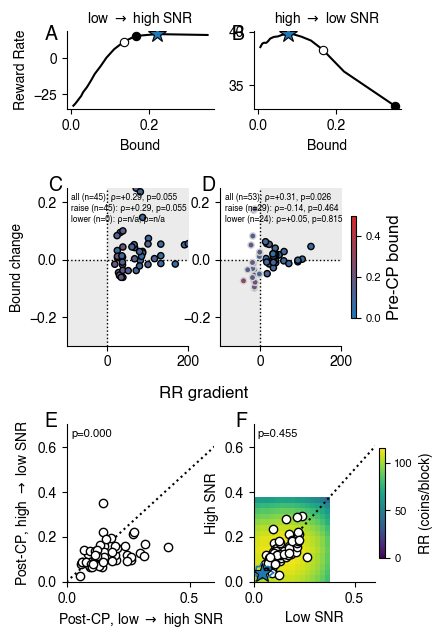

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Figure06.pdf


In [7]:
# ── Publication layout matching MATLAB getPLOT_axes(6, 8.5, [2,4,4], {2,2,2}, 2.0, 1.0) ──
CM       = 1 / 2.54
WID      = 8.5
HTS      = [2.0, 4.0, 4.0]
PSH      = 2.0
PSW      = 1.0
FS       = 12
HEADER_H = 0.6   # cm reserved above Row 1 for the column headers
GRAD_XLIM = (-100, 200)   # shared by both Row 2 panels
YLIM     = (-0.30, 0.25)
PRE_VMIN, PRE_VMAX = 0.0, 0.5

fig_h    = sum(HTS) + PSH * (len(HTS) - 1) + HEADER_H   # 2+4+4 + 2*2 + 0.6 = 14.6 cm
panel_w  = (WID - PSW) / 2                                # 3.75 cm
grid_top = 1 - HEADER_H / fig_h

fig_fmt = plt.figure(figsize=(WID * CM, fig_h * CM))
gs = gridspec.GridSpec(
    3, 2, figure=fig_fmt,
    height_ratios=HTS,
    hspace=PSH / np.mean(HTS),
    wspace=PSW / panel_w,
    left=0, right=1, bottom=0, top=grid_top,
)
axs_fmt = np.array([[fig_fmt.add_subplot(gs[r, c]) for c in range(2)] for r in range(3)])
plt.rcParams.update({'font.size': FS, 'axes.labelsize': FS, 'axes.titlesize': FS, **FONT_RC})

# ── Column headers ────────────────────────────────────────────────────────────
fig_fmt.canvas.draw()
header_y = grid_top + (1 - grid_top) / 2
col_titles = [r'low $\rightarrow$ high SNR', r'high $\rightarrow$ low SNR']
for tt in range(2):
    x_c = np.mean([axs_fmt[0, tt].get_position().x0, axs_fmt[0, tt].get_position().x1])
    fig_fmt.text(x_c, header_y, col_titles[tt], ha='center', va='center', fontsize=10)

# ── Row 1: example subject RR curve ──────────────────────────────────────────
# pre-CP bound = open (white) circle, post-CP bound = filled black circle — shape
# (not color) distinguishes the two, since Row 1 doesn't encode a continuous
# quantity the way Rows 2 and 3 do. Optimal bound stays a blue star throughout.
for tt in range(2):
    xs  = lh_bounds[:, 0] if tt == 0 else hl_bounds[:, 0]
    ys  = lh_bounds[:, 1] if tt == 0 else hl_bounds[:, 1]
    cpt = cp_lh             if tt == 0 else cp_hl
    pp  = EXAMPLE_SUBJECTS[tt]

    prei       = int(np.clip(np.searchsorted(BOUNDS, xs[pp], 'right') - 1, 0, len(BOUNDS) - 1))
    posti      = int(np.clip(np.searchsorted(BOUNDS, ys[pp], 'right') - 1, 0, len(BOUNDS) - 1))
    cp_idx_arr = np.where(cp_steps_by_cond[tt] == cpt[pp])[0]
    cp_idx     = int(cp_idx_arr[0]) if len(cp_idx_arr) else 0

    rrs    = pmats[tt][prei, :, cp_idx]
    kernel = np.ones(3) / 3
    rrs_sm = np.convolve(rrs, kernel, mode='same')
    rrs_sm[[0, -1]] = rrs[[0, -1]]
    maxi_sm = int(np.nanargmax(rrs_sm))  # smoothed argmax for display marker

    ax1 = axs_fmt[0, tt]
    ax1.plot(BOUNDS, rrs_sm, 'k-')
    ax1.plot(BOUNDS[prei],    rrs_sm[prei],    'o', markerfacecolor='white',
             markersize=6, markeredgecolor='k', markeredgewidth=0.8)
    ax1.plot(BOUNDS[maxi_sm], rrs_sm[maxi_sm], '*', color='tab:blue',
             markersize=13, markeredgecolor='k', markeredgewidth=0.8)
    ax1.plot(BOUNDS[posti],   rrs_sm[posti],   'o', markerfacecolor='black',
             markersize=6, markeredgecolor='k', markeredgewidth=0.8)
    ax1.set_xlabel('Bound')
    if tt == 0:
        ax1.set_ylabel('Reward Rate')
    add_panel_label(ax1, chr(65 + tt))

# ── Row 2: bound change vs. RR gradient, split by direction ─────────────────
# Fill color = pre-CP bound on a dedicated blue-red gradient (PRE_BOUND_CMAP,
# distinct from Row 3 panel F's viridis RR heatmap); edge color = sign of
# gradient (black = positive/should-raise, gray = negative/should-lower). No
# trend line — the annotated pooled and per-branch Spearman correlations (each
# with its own n) are the summary statistics for the panel. Both panels share
# GRAD_XLIM so gradient magnitudes are directly comparable between conditions.
def _p(p):
    if not np.isfinite(p):
        return "n/a"
    return f"{p:.3f}" if p >= 0.001 else "<0.001"

def _rho(rho):
    return f"{rho:+.2f}" if np.isfinite(rho) else "n/a"

for tt in range(2):
    d, grad, pre = all_deltas[tt], all_gradient[tt], all_pre[tt]
    fin = np.isfinite(d) & np.isfinite(grad) & np.isfinite(pre) & (grad != 0)
    d, grad, pre = d[fin], grad[fin], pre[fin]

    ax2 = axs_fmt[1, tt]
    ax2.fill_between([GRAD_XLIM[0], 0], YLIM[0], 0, color='0.92', zorder=0)
    ax2.fill_between([0, GRAD_XLIM[1]], 0, YLIM[1], color='0.92', zorder=0)
    ax2.axhline(0, color='k', linestyle=':', linewidth=1, zorder=1)
    ax2.axvline(0, color='k', linestyle=':', linewidth=1, zorder=1)

    for branch, edgecolor, mask in [('should-raise', 'black', grad > 0),
                                     ('should-lower', 'lightgray', grad < 0)]:
        sc = ax2.scatter(grad[mask], d[mask], c=pre[mask], cmap=PRE_BOUND_CMAP,
                         vmin=PRE_VMIN, vmax=PRE_VMAX, edgecolors=edgecolor,
                         linewidths=1.0, s=20, zorder=2)

    sa = spearman_pooled[TITLES[tt]]
    sr = spearman_branch[(TITLES[tt], 'should-raise')]
    sl = spearman_branch[(TITLES[tt], 'should-lower')]

    annot = (f"all (n={sa['n']}): ρ={_rho(sa['rho'])}, p={_p(sa['p'])}\n"
             f"raise (n={sr['n']}): ρ={_rho(sr['rho'])}, p={_p(sr['p'])}\n"
             f"lower (n={sl['n']}): ρ={_rho(sl['rho'])}, p={_p(sl['p'])}")
    ax2.text(0.04, 0.97, annot, transform=ax2.transAxes, ha='left', va='top',
             fontsize=FS - 6, linespacing=1.3)

    ax2.set_xlim(GRAD_XLIM)
    ax2.set_ylim(YLIM)
    add_panel_label(ax2, chr(67 + tt))

ax_row2_bottom = min(axs_fmt[1, 0].get_position().y0, axs_fmt[1, 1].get_position().y0)
axs_fmt[1, 0].set_ylabel('Bound change')
cbar = fig_fmt.colorbar(sc, ax=list(axs_fmt[1, :]), shrink=0.65, pad=0.03)
cbar.set_label('Pre-CP bound', fontsize=FS)
cbar.ax.tick_params(labelsize=FS - 4)

fig_fmt.canvas.draw()
x_c = np.mean([axs_fmt[1, 0].get_position().x0, axs_fmt[1, 1].get_position().x1])
fig_fmt.text(x_c, ax_row2_bottom - 0.07, 'RR gradient', ha='center',
             va='top', fontsize=FS)

# ── Row 3, panel E: post-CP bound comparison (LowHigh vs. HighLow) ──────────
ax3 = axs_fmt[2, 0]
xs, ys = lh_bounds[:, 1], hl_bounds[:, 1]
Lg = np.isfinite(xs) & np.isfinite(ys)
ax3.plot([0, 0.8], [0, 0.8], 'k:')
ax3.plot(xs[Lg], ys[Lg], 'ko', markerfacecolor='white')
_, p_e = scipy.stats.wilcoxon(xs[Lg], ys[Lg])
ax3.text(0.03, 0.97, f'p={p_e:.3f}', transform=ax3.transAxes, ha='left', va='top',
          fontsize=FS - 4)
add_panel_label(ax3, 'E')
ax3.set_xlabel(r'Post-CP, low $\rightarrow$ high SNR')
ax3.set_ylabel(r'Post-CP, high $\rightarrow$ low SNR')
ax3.set_xlim(0, 0.6)
ax3.set_ylim(0, 0.7)

# ── Row 3, panel F: Low vs. High stable-SNR bounds, over the RR landscape ───
# (stable_rr_matrix computed above). Near-optimal (>=95% of max RR) region
# outlined with a thin blue contour and the peak marked with a blue star,
# matching Figure05_mixedVsBlockedSNR.ipynb's heatmap styling (contour) and
# this notebook's own Row 1 convention (star, rather than Figure 5's circle).
ax4 = axs_fmt[2, 1]
xs, ys = lo_bounds[:, 0], hi_bounds[:, 0]
Lg = np.isfinite(xs) & np.isfinite(ys)

b_min, b_max = BOUNDS[0], BOUNDS[-1]
im = ax4.imshow(stable_rr_matrix, origin='lower',
                 extent=[b_min - 0.025, b_max + 0.025, b_min - 0.025, b_max + 0.025],
                 aspect='auto', vmin=0, vmax=stable_rr_matrix.max(), cmap='viridis', zorder=0)
ax4.plot([0, 0.8], [0, 0.8], 'k:', zorder=1)
ax4.plot(xs[Lg], ys[Lg], 'ko', markerfacecolor='white', zorder=2)

# Contour and peak marker are drawn last (above the participant scatter) so they
# stay visible even where the RR optimum coincides with where subjects cluster
# (as it does here) — matching Figure05_mixedVsBlockedSNR.ipynb's draw order.
near_opt = stable_rr_matrix >= 0.95 * stable_rr_matrix.max()
lo_grid, hi_grid = np.meshgrid(BOUNDS, BOUNDS)
ax4.contour(lo_grid, hi_grid, near_opt.astype(float), levels=[0.5],
            colors='tab:blue', linewidths=1.2, zorder=3)

opt_hi_idx, opt_lo_idx = np.unravel_index(stable_rr_matrix.argmax(), stable_rr_matrix.shape)
ax4.plot(BOUNDS[opt_lo_idx], BOUNDS[opt_hi_idx], '*', color='tab:blue',
         markersize=14, markeredgecolor='k', markeredgewidth=0.8, zorder=4)

_, p_f = scipy.stats.wilcoxon(xs[Lg], ys[Lg])
ax4.text(0.03, 0.97, f'p={p_f:.3f}', transform=ax4.transAxes, ha='left', va='top',
          fontsize=FS - 4)
add_panel_label(ax4, 'F')
ax4.set_xlabel('Low SNR')
ax4.set_ylabel('High SNR')
ax4.set_xlim(0, 0.6)
ax4.set_ylim(0, 0.7)

cbar_f = fig_fmt.colorbar(im, ax=ax4, shrink=0.7, pad=0.03)
cbar_f.set_label('RR (coins/block)', fontsize=FS - 2)
cbar_f.ax.tick_params(labelsize=FS - 4)

for ax in axs_fmt.flat:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

out = FIGURES_DIR / 'Figure06.pdf'
fig_fmt.savefig(out, dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {out}')